Premier League 2005/06 To 2026/27 Games Won By Possession Share

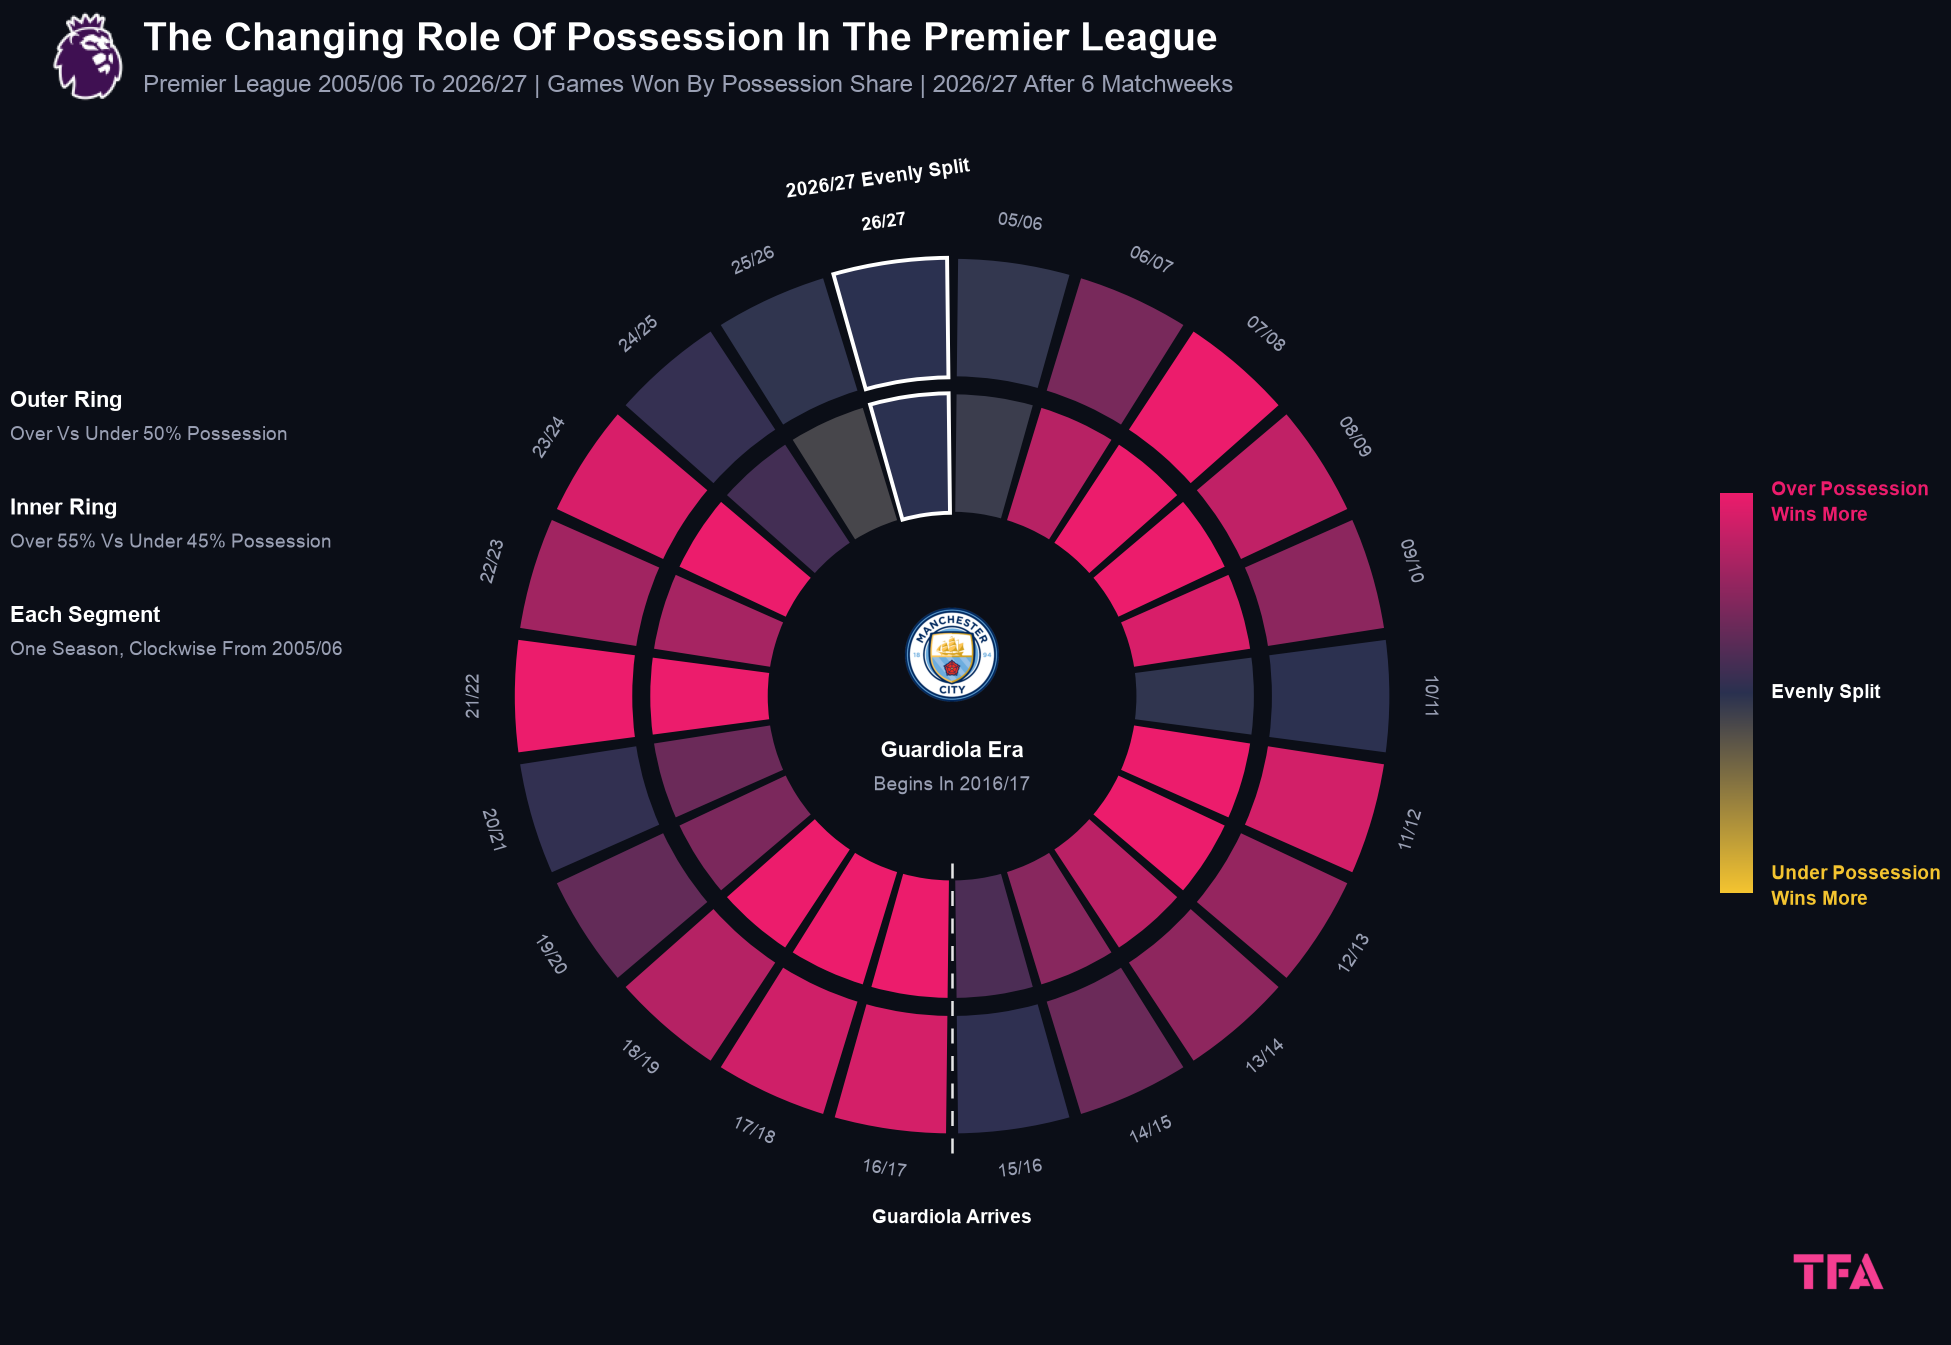

In [8]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

EVEN_50 = 20
EVEN_55_45 = 8

OVER_50 = np.array([149, 154, 174, 167, 158, 135, 172, 154, 169, 155, 137, 179, 169, 181, 154, 150, 184, 167, 181, 145, 137, EVEN_50], dtype=float)
UNDER_50 = np.array([152, 127, 105, 115, 124, 134, 113, 118, 132, 132, 135, 117, 112, 128, 134, 147, 107, 124, 117, 141, 139, EVEN_50], dtype=float)

OVER_55 = np.array([77, 88, 100, 113, 105, 81, 123, 99, 120, 106, 88, 140, 130, 151, 116, 115, 138, 124, 146, 99, 83, EVEN_55_45], dtype=float)
UNDER_45 = np.array([80, 62, 49, 62, 68, 82, 58, 59, 84, 84, 81, 72, 75, 91, 95, 98, 76, 91, 80, 93, 89, EVEN_55_45], dtype=float)

seasons = [f"{str(y)[2:]}/{str(y + 1)[2:]}" for y in range(2005, 2027)]
n = len(seasons)
rows = np.arange(n)
seg = 2 * np.pi / n
theta = (rows + 0.5) * seg

share_50 = OVER_50 / (OVER_50 + UNDER_50) * 100
share_55 = OVER_55 / (OVER_55 + UNDER_45) * 100

cmap = LinearSegmentedColormap.from_list("share", ["#F4C430", "#2A3150", "#EC1C6C"])
norm = Normalize(vmin=38, vmax=62)

DPI = 100
W, H = 2048, 1536

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def tangent_rotation(angle_rad):
    deg = np.degrees(angle_rad) % 360
    rot = -deg
    if 90 < deg < 270:
        rot += 180
    return rot


fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")

ax = fig.add_axes([0.2315, 0.07, 0.537, 0.716], projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_ylim(0, 1.38)

RING_H = 0.30
OUTER_BOTTOM = 0.80
INNER_BOTTOM = 0.46

ax.bar(theta, RING_H, width=seg * 0.92, bottom=OUTER_BOTTOM, color=cmap(norm(share_50)), edgecolor="#0B0E17", linewidth=1.5, zorder=3)
ax.bar(theta, RING_H, width=seg * 0.92, bottom=INNER_BOTTOM, color=cmap(norm(share_55)), edgecolor="#0B0E17", linewidth=1.5, zorder=3)

ax.bar(theta[-1], RING_H, width=seg * 0.92, bottom=OUTER_BOTTOM, color="none", edgecolor="#FFFFFF", linewidth=2.8, zorder=4)
ax.bar(theta[-1], RING_H, width=seg * 0.92, bottom=INNER_BOTTOM, color="none", edgecolor="#FFFFFF", linewidth=2.8, zorder=4)

boundary = 11 * seg
ax.plot([boundary, boundary], [0.42, 1.15], color="#FFFFFF", linestyle=(0, (6, 5)), linewidth=1.8, alpha=0.9, zorder=5)

for i, label in enumerate(seasons):
    ax.text(theta[i], 1.20, label, color="#FFFFFF" if i == n - 1 else "#9AA0B4", fontsize=13, fontweight="bold" if i == n - 1 else "normal", ha="center", va="center", rotation=tangent_rotation(theta[i]), rotation_mode="anchor", zorder=6)

ax.text(boundary, 1.31, "Guardiola Arrives", color="#FFFFFF", fontsize=14, fontweight="bold", ha="center", va="center", rotation=tangent_rotation(boundary), rotation_mode="anchor", zorder=6)
ax.text(theta[-1], 1.31, "2026/27 Evenly Split", color="#FFFFFF", fontsize=14, fontweight="bold", ha="center", va="center", rotation=tangent_rotation(theta[-1]), rotation_mode="anchor", zorder=6)

ax.set_axis_off()

ax_city = fig.add_axes([0.4731, 0.4192, 0.0537, 0.0716])
city_path = find_logo("Manchester City")
if city_path:
    ax_city.imshow(np.asarray(Image.open(city_path).convert("RGBA")))
ax_city.axis("off")
fig.text(0.5, 0.392, "Guardiola Era", color="#FFFFFF", fontsize=16, fontweight="bold", ha="center", va="center")
fig.text(0.5, 0.370, "Begins In 2016/17", color="#9AA0B4", fontsize=14, ha="center", va="center")

fig.text(0.04, 0.62, "Outer Ring", color="#FFFFFF", fontsize=16, fontweight="bold", ha="left", va="center")
fig.text(0.04, 0.598, "Over Vs Under 50% Possession", color="#9AA0B4", fontsize=14, ha="left", va="center")
fig.text(0.04, 0.55, "Inner Ring", color="#FFFFFF", fontsize=16, fontweight="bold", ha="left", va="center")
fig.text(0.04, 0.528, "Over 55% Vs Under 45% Possession", color="#9AA0B4", fontsize=14, ha="left", va="center")
fig.text(0.04, 0.48, "Each Segment", color="#FFFFFF", fontsize=16, fontweight="bold", ha="left", va="center")
fig.text(0.04, 0.458, "One Season, Clockwise From 2005/06", color="#9AA0B4", fontsize=14, ha="left", va="center")

ax_cb = fig.add_axes([0.875, 0.30, 0.016, 0.26])
ax_cb.imshow(np.linspace(1, 0, 256).reshape(-1, 1), aspect="auto", cmap=cmap, extent=[0, 1, 0, 1])
ax_cb.axis("off")
fig.text(0.90, 0.555, "Over Possession\nWins More", color="#EC1C6C", fontsize=14, fontweight="bold", ha="left", va="center", linespacing=1.4)
fig.text(0.90, 0.43, "Evenly Split", color="#FFFFFF", fontsize=14, fontweight="bold", ha="left", va="center")
fig.text(0.90, 0.305, "Under Possession\nWins More", color="#F4C430", fontsize=14, fontweight="bold", ha="left", va="center", linespacing=1.4)

fig.text(0.105, 0.855, "The Changing Role Of Possession In The Premier League", color="#FFFFFF", fontsize=28, fontweight="bold", ha="left", va="center")
fig.text(0.105, 0.825, "Premier League 2005/06 To 2026/27 | Games Won By Possession Share | 2026/27 After 6 Matchweeks", color="#9AA0B4", fontsize=17, ha="left", va="center")

ax_tfa = fig.add_axes([0.904, 0.015, 0.077, 0.077])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.04, 0.814, 0.061, 0.061])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

fig.text(0.5, 0.018, " ", color="#9AA0B4", fontsize=14, ha="center", va="center")

plt.show()

Premier League 2005/06 To 2026/27 | Win % Of Teams With 60%+ Possession In A Match

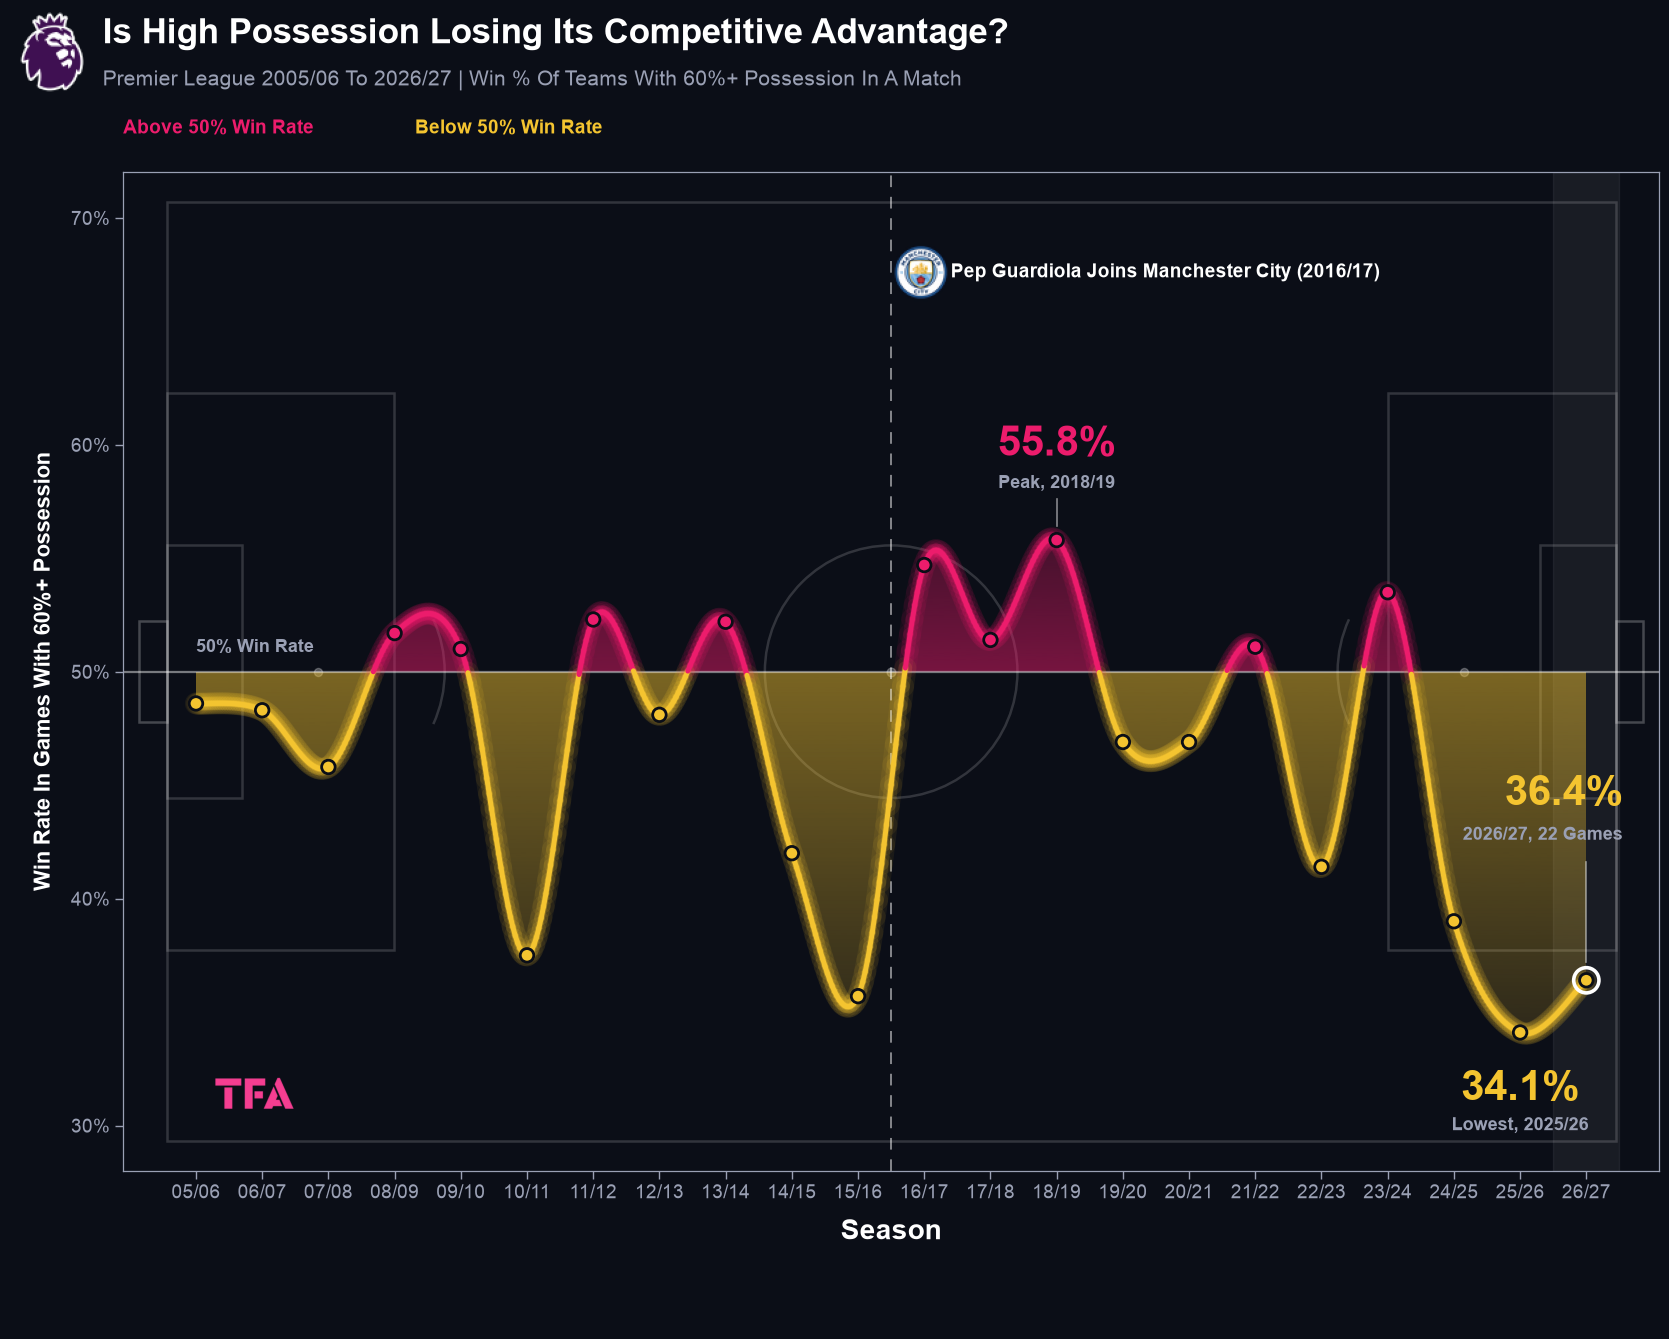

In [44]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import to_rgb
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.patches import Arc, Ellipse, Polygon, Rectangle
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

WIN_RATE = np.array([
    48.6, 48.3, 45.8, 51.7, 51.0, 37.5, 52.3, 48.1, 52.2, 42.0, 35.7,
    54.7, 51.4, 55.8, 46.9, 46.9, 51.1, 41.4, 53.5, 39.0, 34.1, 36.4,
], dtype=float)

seasons = [f"{str(y)[2:]}/{str(y + 1)[2:]}" for y in range(2005, 2027)]
x = np.arange(len(seasons))
last = len(seasons) - 1

DPI = 100
W, H = 2048, 1536

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def load_resized(path, size_px):
    img = Image.open(path).convert("RGBA")
    ratio = size_px / max(img.width, img.height)
    img = img.resize((max(1, int(img.width * ratio)), max(1, int(img.height * ratio))), Image.LANCZOS)
    return np.asarray(img)


def catmull_rom(xs, ys, n=28):
    P = np.column_stack([xs, ys])
    out = []
    for i in range(len(P) - 1):
        p0 = P[i - 1] if i > 0 else P[i]
        p1 = P[i]
        p2 = P[i + 1]
        p3 = P[i + 2] if i + 2 < len(P) else P[i + 1]
        t = np.linspace(0, 1, n, endpoint=False)[:, None]
        seg = 0.5 * ((2 * p1) + (-p0 + p2) * t + (2 * p0 - 5 * p1 + 4 * p2 - p3) * t ** 2 + (-p0 + 3 * p1 - 3 * p2 + p3) * t ** 3)
        out.append(seg)
    out.append(P[-1][None, :])
    R = np.vstack(out)
    return R[:, 0], R[:, 1]


def gradient_fill(ax, xs, ys, base, up, color, edge_y, zorder):
    yb = np.maximum(ys, base) if up else np.minimum(ys, base)
    pts = list(zip(xs, yb)) + [(xs[-1], base), (xs[0], base)]
    patch = Polygon(pts, closed=True, facecolor="none", edgecolor="none", transform=ax.transData)
    ax.add_patch(patch)
    r, g, b = to_rgb(color)
    ramp = np.linspace(0, 1, 256)
    alpha = 0.03 + 0.45 * (ramp if up else (1 - ramp))
    rgba = np.zeros((256, 1, 4))
    rgba[..., 0] = r
    rgba[..., 1] = g
    rgba[..., 2] = b
    rgba[:, 0, 3] = alpha
    extent = [xs[0], xs[-1], base, edge_y] if up else [xs[0], xs[-1], edge_y, base]
    im = ax.imshow(rgba, extent=extent, aspect="auto", origin="upper", zorder=zorder)
    im.set_clip_path(patch)


fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")

AX_RECT = [0.115, 0.115, 0.75, 0.65]
ax = fig.add_axes(AX_RECT)

XL = (-1.1, 22.1)
YL = (28, 72)
AX_W = AX_RECT[2] * W
AX_H = AX_RECT[3] * H
ppx = AX_W / (XL[1] - XL[0])
ppy = AX_H / (YL[1] - YL[0])
k = min(22 * ppx / 105, 0.94 * AX_H / 68)
ux = k / ppx
uy = k / ppy
cx = 10.5
cy = 50.0

xs_s, ys_s = catmull_rom(x, WIN_RATE)

gradient_fill(ax, xs_s, ys_s, 50, True, "#EC1C6C", 62, 1)
gradient_fill(ax, xs_s, ys_s, 50, False, "#F4C430", 28, 1)

ax.set_xlim(*XL)
ax.set_ylim(*YL)
ax.set_xticks(x)
ax.set_xticklabels(seasons)
ax.set_yticks([30, 40, 50, 60, 70])
ax.set_yticklabels(["30%", "40%", "50%", "60%", "70%"])
ax.tick_params(colors="#9AA0B4", labelsize=14, length=6, width=1)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_color("#9AA0B4")
    spine.set_linewidth(0.9)
ax.set_ylabel("Win Rate In Games With 60%+ Possession", color="#FFFFFF", fontsize=16, fontweight="bold", labelpad=12)
ax.set_xlabel("Season", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=12)

pl = cx - 52.5 * ux
pr = cx + 52.5 * ux
line_kw = dict(fill=False, edgecolor="#FFFFFF", alpha=0.16, linewidth=1.8, zorder=0)

ax.add_patch(Rectangle((pl, cy - 34 * uy), 105 * ux, 68 * uy, **line_kw))
ax.add_patch(Ellipse((cx, cy), 2 * 9.15 * ux, 2 * 9.15 * uy, **line_kw))
ax.scatter([cx], [cy], s=40, color="#FFFFFF", alpha=0.25, zorder=0)

ax.add_patch(Rectangle((pl, cy - 20.16 * uy), 16.5 * ux, 40.32 * uy, **line_kw))
ax.add_patch(Rectangle((pr - 16.5 * ux, cy - 20.16 * uy), 16.5 * ux, 40.32 * uy, **line_kw))
ax.add_patch(Rectangle((pl, cy - 9.16 * uy), 5.5 * ux, 18.32 * uy, **line_kw))
ax.add_patch(Rectangle((pr - 5.5 * ux, cy - 9.16 * uy), 5.5 * ux, 18.32 * uy, **line_kw))

spot_l = pl + 11 * ux
spot_r = pr - 11 * ux
ax.scatter([spot_l, spot_r], [cy, cy], s=34, color="#FFFFFF", alpha=0.25, zorder=0)

ang = np.degrees(np.arccos(5.5 / 9.15))
ax.add_patch(Arc((spot_l, cy), 2 * 9.15 * ux, 2 * 9.15 * uy, theta1=-ang, theta2=ang, edgecolor="#FFFFFF", alpha=0.16, linewidth=1.8, zorder=0))
ax.add_patch(Arc((spot_r, cy), 2 * 9.15 * ux, 2 * 9.15 * uy, theta1=180 - ang, theta2=180 + ang, edgecolor="#FFFFFF", alpha=0.16, linewidth=1.8, zorder=0))

ax.add_patch(Rectangle((pl - 2 * ux, cy - 3.66 * uy), 2 * ux, 7.32 * uy, fill=False, edgecolor="#FFFFFF", alpha=0.24, linewidth=1.8, zorder=0))
ax.add_patch(Rectangle((pr, cy - 3.66 * uy), 2 * ux, 7.32 * uy, fill=False, edgecolor="#FFFFFF", alpha=0.24, linewidth=1.8, zorder=0))

ax.axhline(50, color="#FFFFFF", alpha=0.45, linewidth=1.6, zorder=2)
ax.text(0.0, 50.7, "50% Win Rate", color="#9AA0B4", fontsize=13, fontweight="bold", ha="left", va="bottom", zorder=5)
ax.axvline(10.5, color="#FFFFFF", linestyle=(0, (6, 5)), linewidth=1.4, alpha=0.5, zorder=2)
ax.axvspan(last - 0.5, last + 0.5, color="#FFFFFF", alpha=0.06, zorder=0)

segs = np.stack([np.column_stack([xs_s[:-1], ys_s[:-1]]), np.column_stack([xs_s[1:], ys_s[1:]])], axis=1)
mid_y = (ys_s[:-1] + ys_s[1:]) / 2
seg_colors = np.where(mid_y >= 50, "#EC1C6C", "#F4C430")

for lw, a in [(16, 0.07), (10, 0.12), (5, 0.25)]:
    ax.add_collection(LineCollection(segs, colors=seg_colors, linewidths=lw, alpha=a, capstyle="round", zorder=3))
ax.add_collection(LineCollection(segs, colors=seg_colors, linewidths=3.6, capstyle="round", zorder=4))

dot_colors = ["#EC1C6C" if v >= 50 else "#F4C430" for v in WIN_RATE]
ax.scatter(x, WIN_RATE, s=95, color=dot_colors, edgecolor="#0B0E17", linewidth=2, zorder=6)
ax.scatter([last], [WIN_RATE[last]], s=330, facecolor="none", edgecolor="#FFFFFF", linewidth=2.6, zorder=6)

ax.plot([13, 13], [56.4, 57.6], color="#FFFFFF", alpha=0.5, linewidth=1.2, zorder=5)
ax.text(13, 60.0, "55.8%", color="#EC1C6C", fontsize=30, fontweight="bold", ha="center", va="center", zorder=7)
ax.text(13, 58.3, "Peak, 2018/19", color="#9AA0B4", fontsize=13, fontweight="bold", ha="center", va="center", zorder=7)

ax.text(20, 31.6, "34.1%", color="#F4C430", fontsize=30, fontweight="bold", ha="center", va="center", zorder=7)
ax.text(20, 30.0, "Lowest, 2025/26", color="#9AA0B4", fontsize=13, fontweight="bold", ha="center", va="center", zorder=7)

ax.plot([21, 21], [37.2, 41.6], color="#FFFFFF", alpha=0.5, linewidth=1.2, zorder=5)
ax.text(21.55, 44.6, "36.4%", color="#F4C430", fontsize=30, fontweight="bold", ha="right", va="center", zorder=7)
ax.text(21.55, 42.8, "2026/27, 22 Games", color="#9AA0B4", fontsize=13, fontweight="bold", ha="right", va="center", zorder=7)

city_path = find_logo("Manchester City")
if city_path:
    box = OffsetImage(load_resized(city_path, 44), zoom=1)
    ab = AnnotationBbox(box, (10.95, 67.6), frameon=False, box_alignment=(0.5, 0.5), zorder=7)
    ax.add_artist(ab)
ax.text(11.4, 67.6, "Pep Guardiola Joins Manchester City (2016/17)", color="#FFFFFF", fontsize=14, fontweight="bold", ha="left", va="center", zorder=7)

ax.text(0.0, 1.035, "Above 50% Win Rate", transform=ax.transAxes, color="#EC1C6C", fontsize=14, fontweight="bold", ha="left", va="bottom")
ax.text(0.19, 1.035, "Below 50% Win Rate", transform=ax.transAxes, color="#F4C430", fontsize=14, fontweight="bold", ha="left", va="bottom")

fig.text(0.105, 0.855, "Is High Possession Losing Its Competitive Advantage?", color="#FFFFFF", fontsize=25, fontweight="bold", ha="left", va="center")
fig.text(0.105, 0.825, "Premier League 2005/06 To 2026/27 | Win % Of Teams With 60%+ Possession In A Match", color="#9AA0B4", fontsize=15, ha="left", va="center")

ax_tfa = fig.add_axes([0.154, 0.132, 0.067, 0.067])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.046, 0.816, 0.055, 0.055])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

fig.text(0.5, 0.018, " ", color="#9AA0B4", fontsize=14, ha="center", va="center")

plt.show()

Average Distance Covered Per Match By Premier League Teams 2025-2026 And 2026-2027

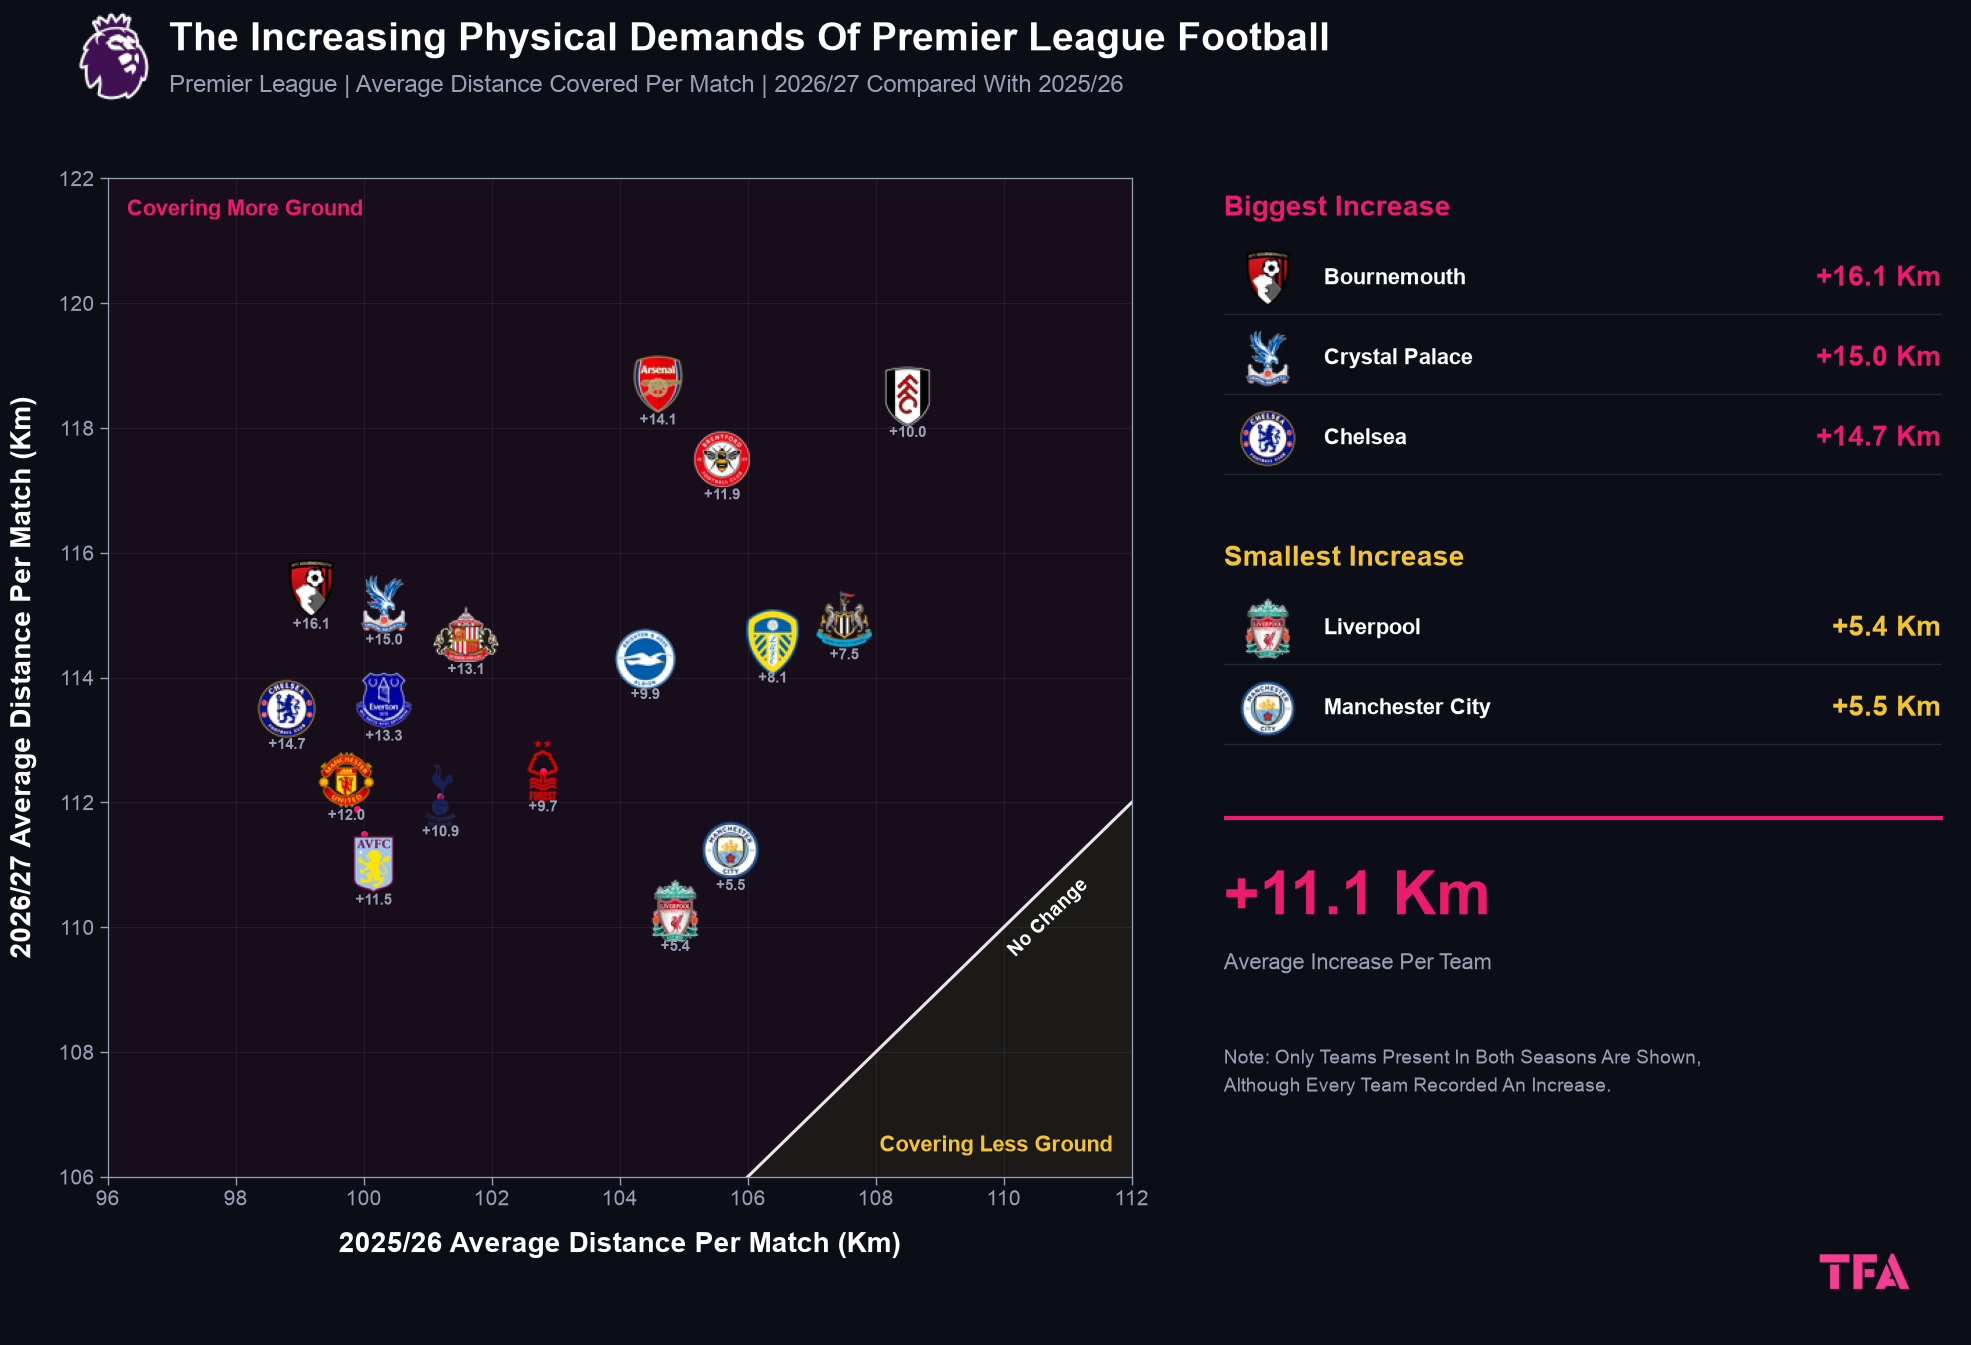

In [4]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

DATA = [
    ("Arsenal", 104.6, 118.7), ("Fulham", 108.5, 118.5), ("Brentford", 105.6, 117.5),
    ("Bournemouth", 99.3, 115.4), ("Crystal Palace", 100.2, 115.2), ("Newcastle United", 107.4, 114.9),
    ("Sunderland", 101.6, 114.7), ("Leeds United", 106.5, 114.6), ("Brighton", 104.4, 114.3),
    ("Everton", 100.3, 113.6), ("Chelsea", 98.8, 113.5), ("Nottingham Forest", 102.8, 112.5),
    ("Tottenham Hotspur", 101.2, 112.1), ("Manchester United", 99.9, 111.9), ("Aston Villa", 100.0, 111.5),
    ("Manchester City", 105.7, 111.2), ("Liverpool", 104.9, 110.3),
]

names = [d[0] for d in DATA]
xs = np.array([d[1] for d in DATA])
ys = np.array([d[2] for d in DATA])
gain = ys - xs
n = len(DATA)

DPI = 100
W, H = 2048, 1536
LOGO_PX = 48

XL = (96, 112)
YL = (106, 122)
AX_RECT = [0.075, 0.115, 0.50, 0.65]
AX_W = AX_RECT[2] * W
AX_H = AX_RECT[3] * H
ppx = AX_W / (XL[1] - XL[0])
ppy = AX_H / (YL[1] - YL[0])
line_angle = np.degrees(np.arctan2(ppy, ppx))

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def load_resized(path, size_px):
    img = Image.open(path).convert("RGBA")
    ratio = size_px / max(img.width, img.height)
    img = img.resize((max(1, int(img.width * ratio)), max(1, int(img.height * ratio))), Image.LANCZOS)
    return np.asarray(img)


fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")

ax = fig.add_axes(AX_RECT)
ax.set_xlim(*XL)
ax.set_ylim(*YL)
ax.set_xticks(range(96, 113, 2))
ax.set_yticks(range(106, 123, 2))
ax.tick_params(colors="#9AA0B4", labelsize=15, length=6, width=1)
ax.grid(True, color="#9AA0B4", alpha=0.10, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_color("#9AA0B4")
    spine.set_linewidth(0.9)
ax.set_xlabel("2025/26 Average Distance Per Match (Km)", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)
ax.set_ylabel("2026/27 Average Distance Per Match (Km)", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)

line_x = np.array([XL[0], XL[1]])
ax.fill_between(line_x, line_x, YL[1], color="#EC1C6C", alpha=0.06, zorder=0)
ax.fill_between(line_x, line_x, YL[0], color="#F4C430", alpha=0.07, zorder=0)

ax.plot(line_x, line_x, color="#FFFFFF", linewidth=2.2, alpha=0.9, zorder=2)
ax.text(110.7, 110.7 - 0.55, "No Change", color="#FFFFFF", fontsize=14, fontweight="bold", ha="center", va="center", rotation=line_angle, rotation_mode="anchor", zorder=5)

ax.text(96.3, 121.5, "Covering More Ground", color="#EC1C6C", fontsize=16, fontweight="bold", ha="left", va="center", zorder=5)
ax.text(111.7, 106.5, "Covering Less Ground", color="#F4C430", fontsize=16, fontweight="bold", ha="right", va="center", zorder=5)

ax.scatter(xs, ys, s=44, color="#EC1C6C", edgecolor="#0B0E17", linewidth=1.5, zorder=4)

pts = ax.transData.transform(np.column_stack([xs, ys]))
pos = pts.copy()
bbox = ax.get_window_extent()
scale = np.array([74.0, 92.0])
pad = 44

for _ in range(1500):
    moved = False
    for i in range(n):
        for j in range(i + 1, n):
            d = (pos[j] - pos[i]) / scale
            sd = np.hypot(d[0], d[1])
            if sd < 1:
                if sd < 1e-6:
                    d = np.array([1.0, 0.5])
                    sd = np.hypot(d[0], d[1])
                vec = d / sd * (1 - sd) / 2 * scale
                pos[i] -= vec
                pos[j] += vec
                moved = True
    pos += (pts - pos) * 0.012
    pos[:, 0] = np.clip(pos[:, 0], bbox.x0 + pad, bbox.x1 - pad)
    pos[:, 1] = np.clip(pos[:, 1], bbox.y0 + pad, bbox.y1 - pad)
    if not moved:
        break

logo_data = ax.transData.inverted().transform(pos)

for i in range(n):
    shift = np.hypot(*(pos[i] - pts[i]))
    if shift > 16:
        ax.plot([xs[i], logo_data[i][0]], [ys[i], logo_data[i][1]], color="#9AA0B4", alpha=0.6, linewidth=1.2, zorder=3)
    path = find_logo(names[i])
    if path:
        box = OffsetImage(load_resized(path, LOGO_PX), zoom=1)
        ab = AnnotationBbox(box, (logo_data[i][0], logo_data[i][1]), frameon=False, box_alignment=(0.5, 0.5), zorder=6)
        ax.add_artist(ab)
    else:
        ax.text(logo_data[i][0], logo_data[i][1], names[i], color="#FFFFFF", fontsize=11, ha="center", va="center", zorder=6)
    ax.annotate(
        f"+{gain[i]:.1f}", (logo_data[i][0], logo_data[i][1]), xytext=(0, -26), textcoords="offset points",
        color="#9AA0B4", fontsize=11, fontweight="bold", ha="center", va="center", zorder=7,
    )

R_W = 0.36 * W
R_H = AX_RECT[3] * H
ax_r = fig.add_axes([0.62, AX_RECT[1], 0.36, AX_RECT[3]])
ax_r.set_xlim(0, R_W)
ax_r.set_ylim(R_H, 0)
ax_r.axis("off")

order = np.argsort(-gain)
top3 = order[:3]
bottom2 = order[::-1][:2]


def rank_row(i, y, color):
    path = find_logo(names[i])
    if path:
        box = OffsetImage(load_resized(path, 46), zoom=1)
        ab = AnnotationBbox(box, (44, y), frameon=False, box_alignment=(0.5, 0.5), zorder=5)
        ax_r.add_artist(ab)
    ax_r.text(100, y, names[i], color="#FFFFFF", fontsize=16, fontweight="bold", ha="left", va="center")
    ax_r.text(R_W - 20, y, f"+{gain[i]:.1f} Km", color=color, fontsize=20, fontweight="bold", ha="right", va="center")
    ax_r.plot([0, R_W - 20], [y + 36, y + 36], color="#9AA0B4", alpha=0.18, linewidth=1)


ax_r.text(0, 30, "Biggest Increase", color="#EC1C6C", fontsize=20, fontweight="bold", ha="left", va="center")
for k, i in enumerate(top3):
    rank_row(i, 100 + k * 80, "#EC1C6C")

ax_r.text(0, 380, "Smallest Increase", color="#F4C430", fontsize=20, fontweight="bold", ha="left", va="center")
for k, i in enumerate(bottom2):
    rank_row(i, 450 + k * 80, "#F4C430")

ax_r.plot([0, R_W - 20], [640, 640], color="#EC1C6C", linewidth=3)
ax_r.text(0, 720, f"+{gain.mean():.1f} Km", color="#EC1C6C", fontsize=44, fontweight="bold", ha="left", va="center")
ax_r.text(0, 785, "Average Increase Per Team", color="#9AA0B4", fontsize=16, ha="left", va="center")

ax_r.text(0, 880, "Note: Only Teams Present In Both Seasons Are Shown,", color="#9AA0B4", fontsize=14, ha="left", va="center")
ax_r.text(0, 908, "Although Every Team Recorded An Increase.", color="#9AA0B4", fontsize=14, ha="left", va="center")

fig.text(0.105, 0.855, "The Increasing Physical Demands Of Premier League Football", color="#FFFFFF", fontsize=28, fontweight="bold", ha="left", va="center")
fig.text(0.105, 0.825, "Premier League | Average Distance Covered Per Match | 2026/27 Compared With 2025/26", color="#9AA0B4", fontsize=17, ha="left", va="center")

ax_tfa = fig.add_axes([0.904, 0.015, 0.077, 0.077])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.04, 0.814, 0.061, 0.061])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

fig.text(0.5, 0.018, " ", color="#9AA0B4", fontsize=14, ha="center", va="center")

plt.show()

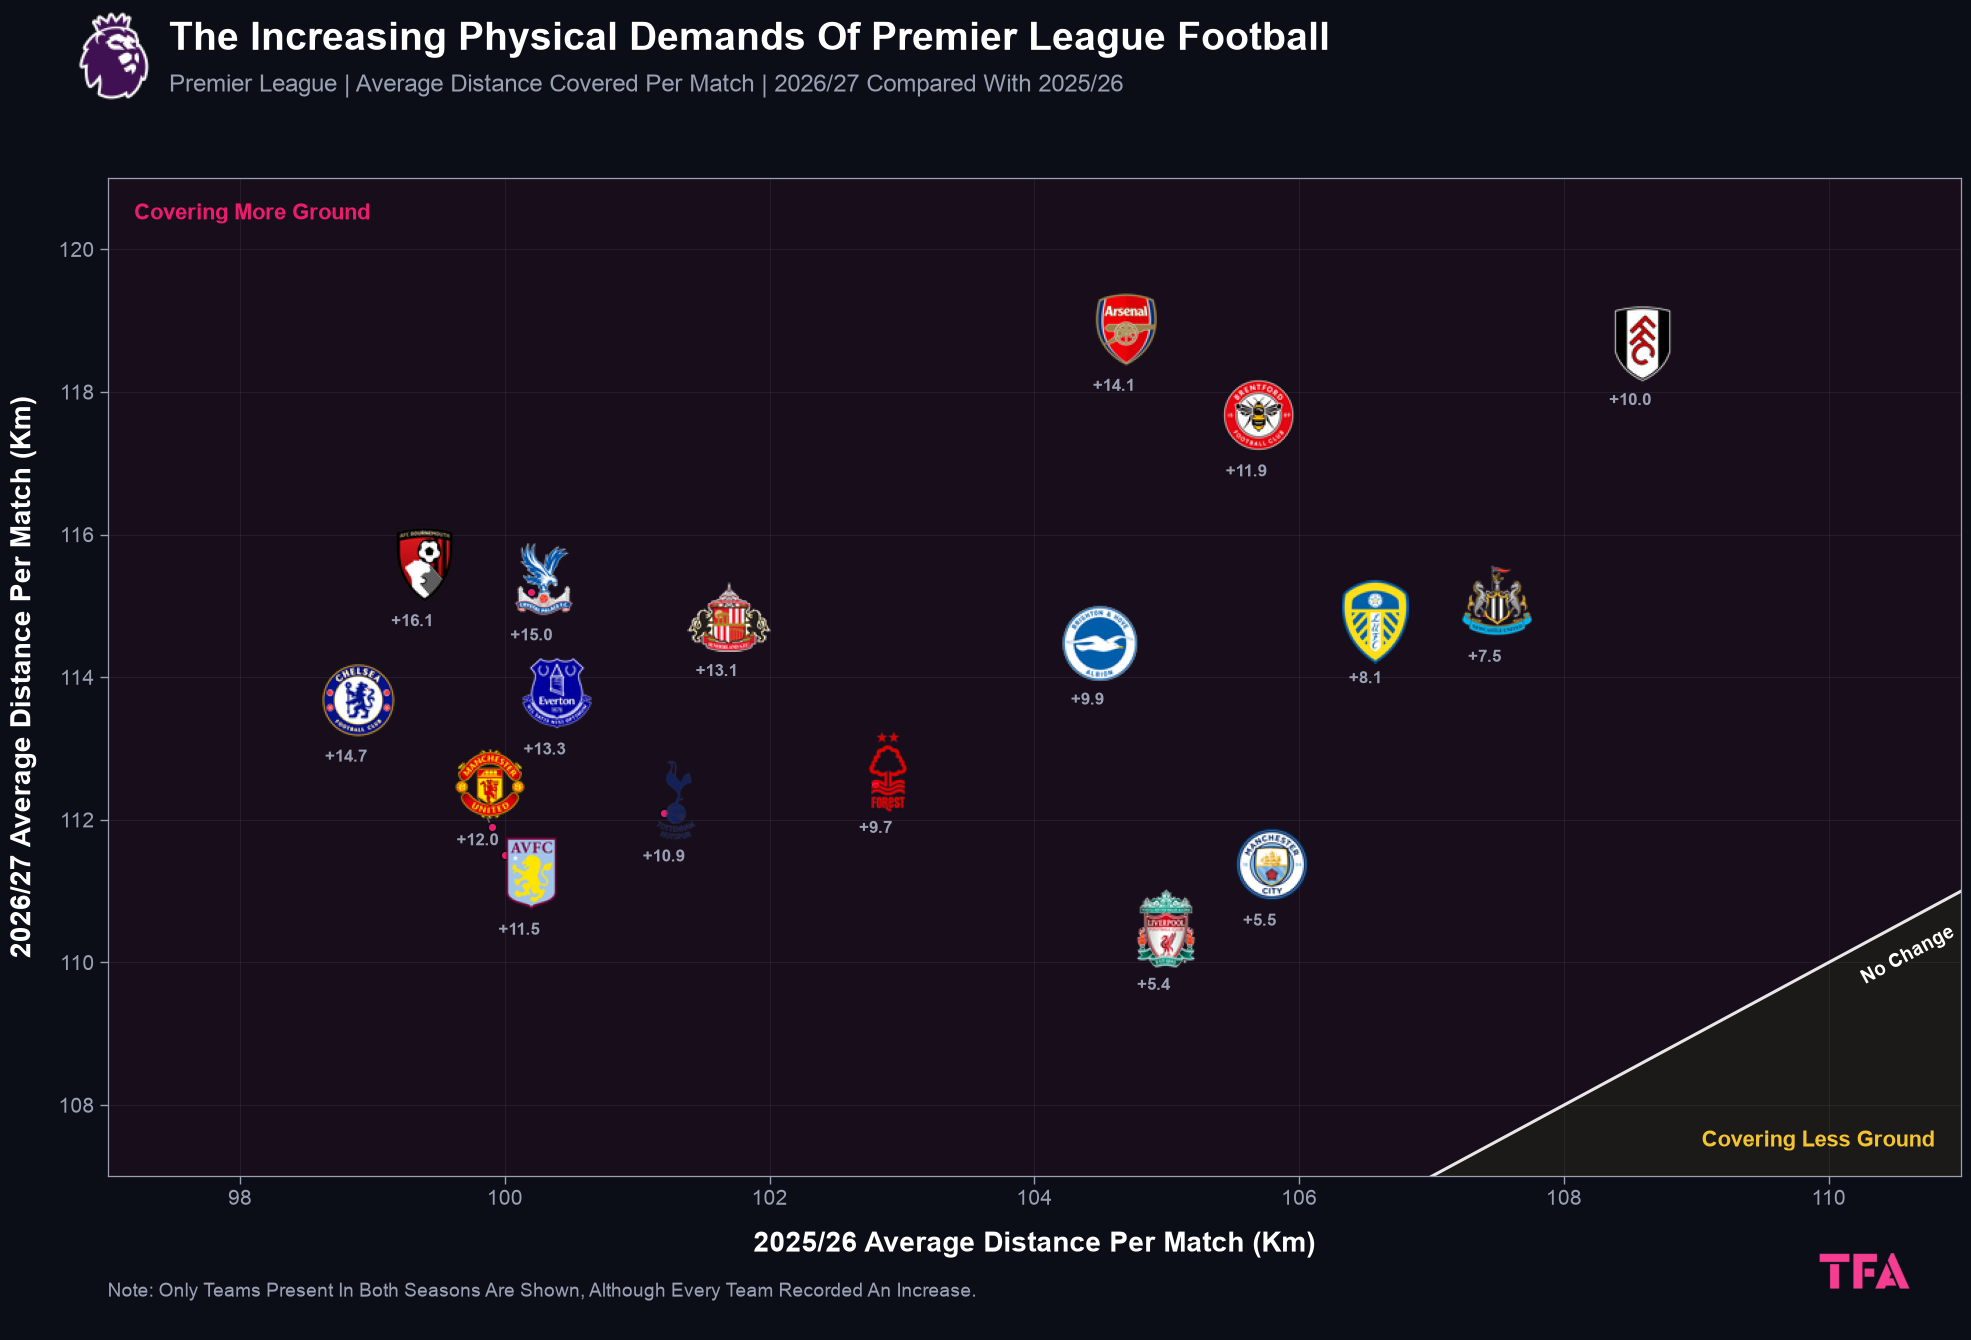

In [9]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

DATA = [
    ("Arsenal", 104.6, 118.7), ("Fulham", 108.5, 118.5), ("Brentford", 105.6, 117.5),
    ("Bournemouth", 99.3, 115.4), ("Crystal Palace", 100.2, 115.2), ("Newcastle United", 107.4, 114.9),
    ("Sunderland", 101.6, 114.7), ("Leeds United", 106.5, 114.6), ("Brighton", 104.4, 114.3),
    ("Everton", 100.3, 113.6), ("Chelsea", 98.8, 113.5), ("Nottingham Forest", 102.8, 112.5),
    ("Tottenham Hotspur", 101.2, 112.1), ("Manchester United", 99.9, 111.9), ("Aston Villa", 100.0, 111.5),
    ("Manchester City", 105.7, 111.2), ("Liverpool", 104.9, 110.3),
]

names = [d[0] for d in DATA]
xs = np.array([d[1] for d in DATA])
ys = np.array([d[2] for d in DATA])
gain = ys - xs
n = len(DATA)

DPI = 100
W, H = 2048, 1536
LOGO_PX = 60

XL = (97, 111)
YL = (107, 121)
AX_RECT = [0.075, 0.115, 0.905, 0.65]
AX_W = AX_RECT[2] * W
AX_H = AX_RECT[3] * H
ppx = AX_W / (XL[1] - XL[0])
ppy = AX_H / (YL[1] - YL[0])
line_angle = np.degrees(np.arctan2(ppy, ppx))

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def load_resized(path, size_px):
    img = Image.open(path).convert("RGBA")
    ratio = size_px / max(img.width, img.height)
    img = img.resize((max(1, int(img.width * ratio)), max(1, int(img.height * ratio))), Image.LANCZOS)
    return np.asarray(img)


fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")

ax = fig.add_axes(AX_RECT)
ax.set_xlim(*XL)
ax.set_ylim(*YL)
ax.set_xticks(range(98, 111, 2))
ax.set_yticks(range(108, 121, 2))
ax.tick_params(colors="#9AA0B4", labelsize=15, length=6, width=1)
ax.grid(True, color="#9AA0B4", alpha=0.10, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_color("#9AA0B4")
    spine.set_linewidth(0.9)
ax.set_xlabel("2025/26 Average Distance Per Match (Km)", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)
ax.set_ylabel("2026/27 Average Distance Per Match (Km)", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)

line_x = np.array([XL[0], XL[1]])
ax.fill_between(line_x, line_x, YL[1], color="#EC1C6C", alpha=0.06, zorder=0)
ax.fill_between(line_x, line_x, YL[0], color="#F4C430", alpha=0.07, zorder=0)

ax.plot(line_x, line_x, color="#FFFFFF", linewidth=2.2, alpha=0.9, zorder=2)
ax.text(110.6, 110.6 - 0.5, "No Change", color="#FFFFFF", fontsize=14, fontweight="bold", ha="center", va="center", rotation=line_angle, rotation_mode="anchor", zorder=5)

ax.text(97.2, 120.5, "Covering More Ground", color="#EC1C6C", fontsize=16, fontweight="bold", ha="left", va="center", zorder=5)
ax.text(110.8, 107.5, "Covering Less Ground", color="#F4C430", fontsize=16, fontweight="bold", ha="right", va="center", zorder=5)

ax.scatter(xs, ys, s=44, color="#EC1C6C", edgecolor="#0B0E17", linewidth=1.5, zorder=4)

pts = ax.transData.transform(np.column_stack([xs, ys]))
pos = pts.copy()
bbox = ax.get_window_extent()
scale = np.array([84.0, 104.0])
pad = 50

for _ in range(1500):
    moved = False
    for i in range(n):
        for j in range(i + 1, n):
            d = (pos[j] - pos[i]) / scale
            sd = np.hypot(d[0], d[1])
            if sd < 1:
                if sd < 1e-6:
                    d = np.array([1.0, 0.5])
                    sd = np.hypot(d[0], d[1])
                vec = d / sd * (1 - sd) / 2 * scale
                pos[i] -= vec
                pos[j] += vec
                moved = True
    pos += (pts - pos) * 0.012
    pos[:, 0] = np.clip(pos[:, 0], bbox.x0 + pad, bbox.x1 - pad)
    pos[:, 1] = np.clip(pos[:, 1], bbox.y0 + pad, bbox.y1 - pad)
    if not moved:
        break

logo_data = ax.transData.inverted().transform(pos)

for i in range(n):
    shift = np.hypot(*(pos[i] - pts[i]))
    if shift > 18:
        ax.plot([xs[i], logo_data[i][0]], [ys[i], logo_data[i][1]], color="#9AA0B4", alpha=0.6, linewidth=1.2, zorder=3)
    path = find_logo(names[i])
    if path:
        box = OffsetImage(load_resized(path, LOGO_PX), zoom=1)
        ab = AnnotationBbox(box, (logo_data[i][0], logo_data[i][1]), frameon=False, box_alignment=(0.35, 0.35), zorder=6)
        ax.add_artist(ab)
    else:
        ax.text(logo_data[i][0], logo_data[i][1], names[i], color="#FFFFFF", fontsize=11, ha="center", va="center", zorder=6)
    ax.annotate(
        f"+{gain[i]:.1f}", (logo_data[i][0], logo_data[i][1]), xytext=(0, -32), textcoords="offset points",
        color="#9AA0B4", fontsize=12, fontweight="bold", ha="center", va="center", zorder=7,
    )

fig.text(0.105, 0.855, "The Increasing Physical Demands Of Premier League Football", color="#FFFFFF", fontsize=28, fontweight="bold", ha="left", va="center")
fig.text(0.105, 0.825, "Premier League | Average Distance Covered Per Match | 2026/27 Compared With 2025/26", color="#9AA0B4", fontsize=17, ha="left", va="center")

ax_tfa = fig.add_axes([0.904, 0.015, 0.077, 0.077])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.04, 0.814, 0.061, 0.061])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

fig.text(0.075, 0.04, "Note: Only Teams Present In Both Seasons Are Shown, Although Every Team Recorded An Increase.", color="#9AA0B4", fontsize=14, ha="left", va="center")

plt.show()

Average Fast Breaks Per Match In The Premier League 2026-2027

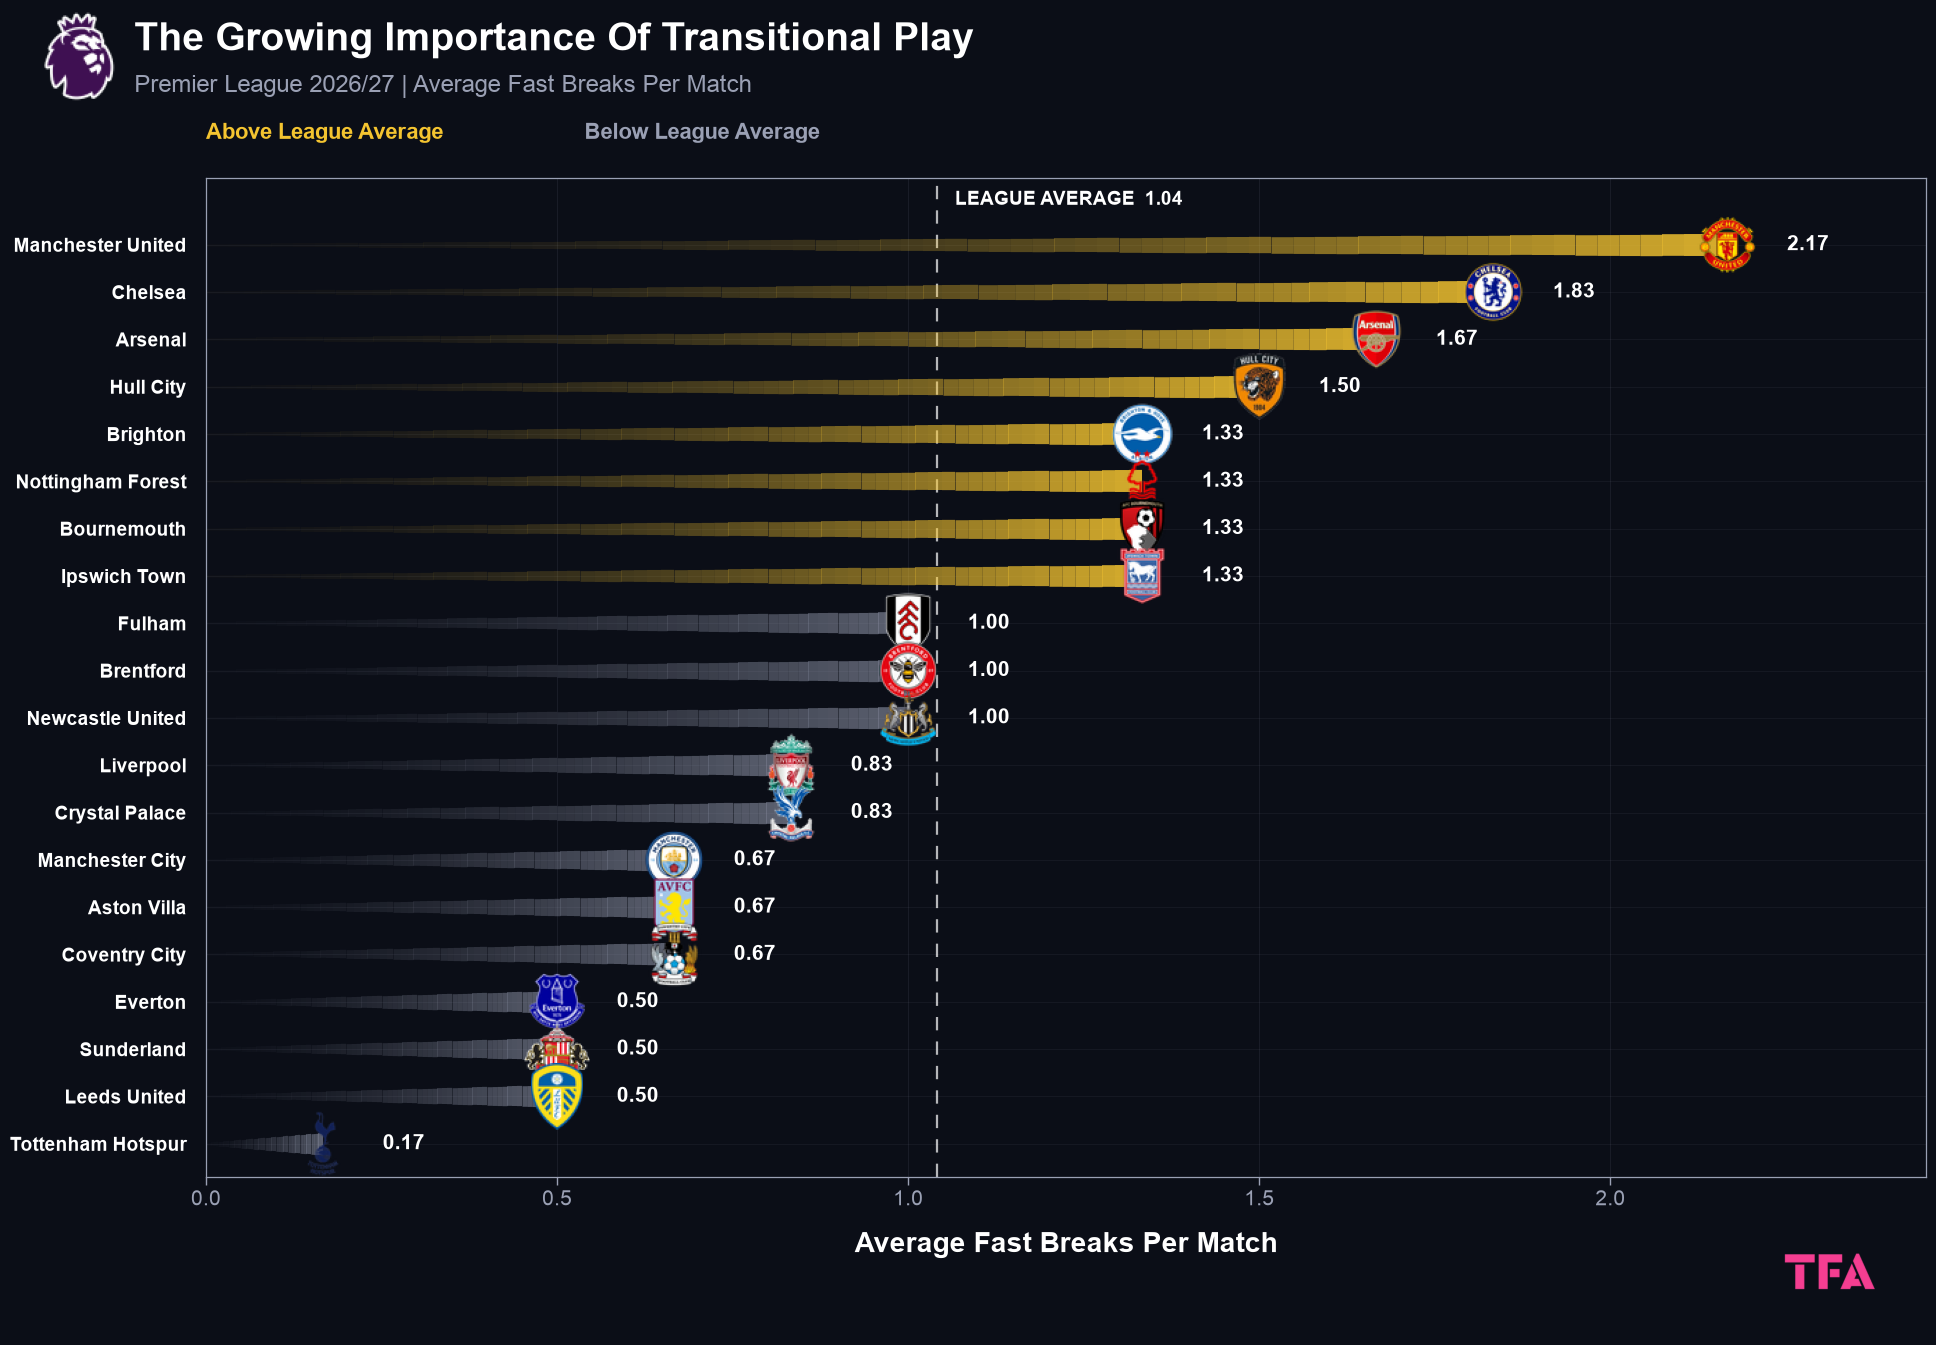

In [11]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import to_rgba
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

MATCHES = 6

TOTALS = {
    "Manchester United": 13, "Arsenal": 10, "Manchester City": 4, "Tottenham Hotspur": 1,
    "Fulham": 6, "Brentford": 6, "Chelsea": 11, "Brighton": 8, "Nottingham Forest": 8,
    "Everton": 3, "Sunderland": 3, "Newcastle United": 6, "Liverpool": 5, "Bournemouth": 8,
    "Ipswich Town": 8, "Aston Villa": 4, "Leeds United": 3, "Crystal Palace": 5,
    "Hull City": 9, "Coventry City": 4,
}

rows = sorted([(t, v / MATCHES) for t, v in TOTALS.items()], key=lambda r: -r[1])
names = [r[0] for r in rows]
vals = np.array([r[1] for r in rows])
ypos = np.arange(len(rows))
avg_v = vals.mean()

DPI = 100
W, H = 2048, 1536
LOGO_PX = 48

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def load_resized(path, size_px):
    img = Image.open(path).convert("RGBA")
    ratio = size_px / max(img.width, img.height)
    img = img.resize((max(1, int(img.width * ratio)), max(1, int(img.height * ratio))), Image.LANCZOS)
    return np.asarray(img)


def comet(ax, v, y, color, max_w, max_a, z):
    k = 70
    xs = np.linspace(0, v, k + 1)
    segs = [[(xs[j], y), (xs[j + 1], y)] for j in range(k)]
    t = np.linspace(0, 1, k)
    cols = [to_rgba(color, 0.02 + max_a * tt ** 1.7) for tt in t]
    ax.add_collection(LineCollection(segs, colors=cols, linewidths=2 + max_w * t, capstyle="butt", zorder=z))


fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")

ax = fig.add_axes([0.14, 0.115, 0.84, 0.65])
ax.set_xlim(0, 2.45)
ax.set_ylim(19.7, -1.4)
ax.set_xticks([0, 0.5, 1.0, 1.5, 2.0])
ax.set_yticks(ypos)
ax.set_yticklabels(names)
ax.tick_params(axis="x", colors="#9AA0B4", labelsize=15, length=6, width=1)
ax.tick_params(axis="y", colors="#FFFFFF", labelsize=14, length=0, pad=14)
for lab in ax.get_yticklabels():
    lab.set_fontweight("bold")
    lab.set_color("#FFFFFF")
ax.grid(True, axis="x", color="#9AA0B4", alpha=0.10, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_color("#9AA0B4")
    spine.set_linewidth(0.9)
ax.set_xlabel("Average Fast Breaks Per Match", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)

ax.hlines(ypos, 0, 2.45, color="#9AA0B4", alpha=0.07, linewidth=0.8, zorder=1)

ax.axvline(avg_v, color="#FFFFFF", linestyle=(0, (6, 5)), linewidth=1.6, alpha=0.7, zorder=2)
ax.text(avg_v + 0.025, -0.95, f"LEAGUE AVERAGE  {avg_v:.2f}", color="#FFFFFF", fontsize=14, fontweight="bold", va="center", ha="left")

for i, (name, v) in enumerate(rows):
    if v >= avg_v:
        comet(ax, v, i, "#F4C430", 14, 0.85, 3)
    else:
        comet(ax, v, i, "#9AA0B4", 14, 0.55, 3)

    path = find_logo(name)
    if path:
        box = OffsetImage(load_resized(path, LOGO_PX), zoom=1)
        ab = AnnotationBbox(box, (v, i), frameon=False, box_alignment=(0.5, 0.5), zorder=6)
        ax.add_artist(ab)
    else:
        ax.text(v, i, name, color="#FFFFFF", fontsize=11, ha="center", va="center", zorder=6)
    ax.text(v + 0.085, i, f"{v:.2f}", color="#FFFFFF", fontsize=15, fontweight="bold", va="center", ha="left", zorder=6)

ax.text(0.0, 1.035, "Above League Average", transform=ax.transAxes, color="#F4C430", fontsize=16, fontweight="bold", ha="left", va="bottom")
ax.text(0.22, 1.035, "Below League Average", transform=ax.transAxes, color="#9AA0B4", fontsize=16, fontweight="bold", ha="left", va="bottom")

fig.text(0.105, 0.855, "The Growing Importance Of Transitional Play", color="#FFFFFF", fontsize=28, fontweight="bold", ha="left", va="center")
fig.text(0.105, 0.825, "Premier League 2026/27 | Average Fast Breaks Per Match", color="#9AA0B4", fontsize=17, ha="left", va="center")

ax_tfa = fig.add_axes([0.904, 0.015, 0.077, 0.077])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.04, 0.814, 0.061, 0.061])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

fig.text(0.5, 0.018, " ", color="#9AA0B4", fontsize=14, ha="center", va="center")

plt.show()

Average Build-Up Sequences And Build-Up Attacks Per Match In The Premier League 2026-2027

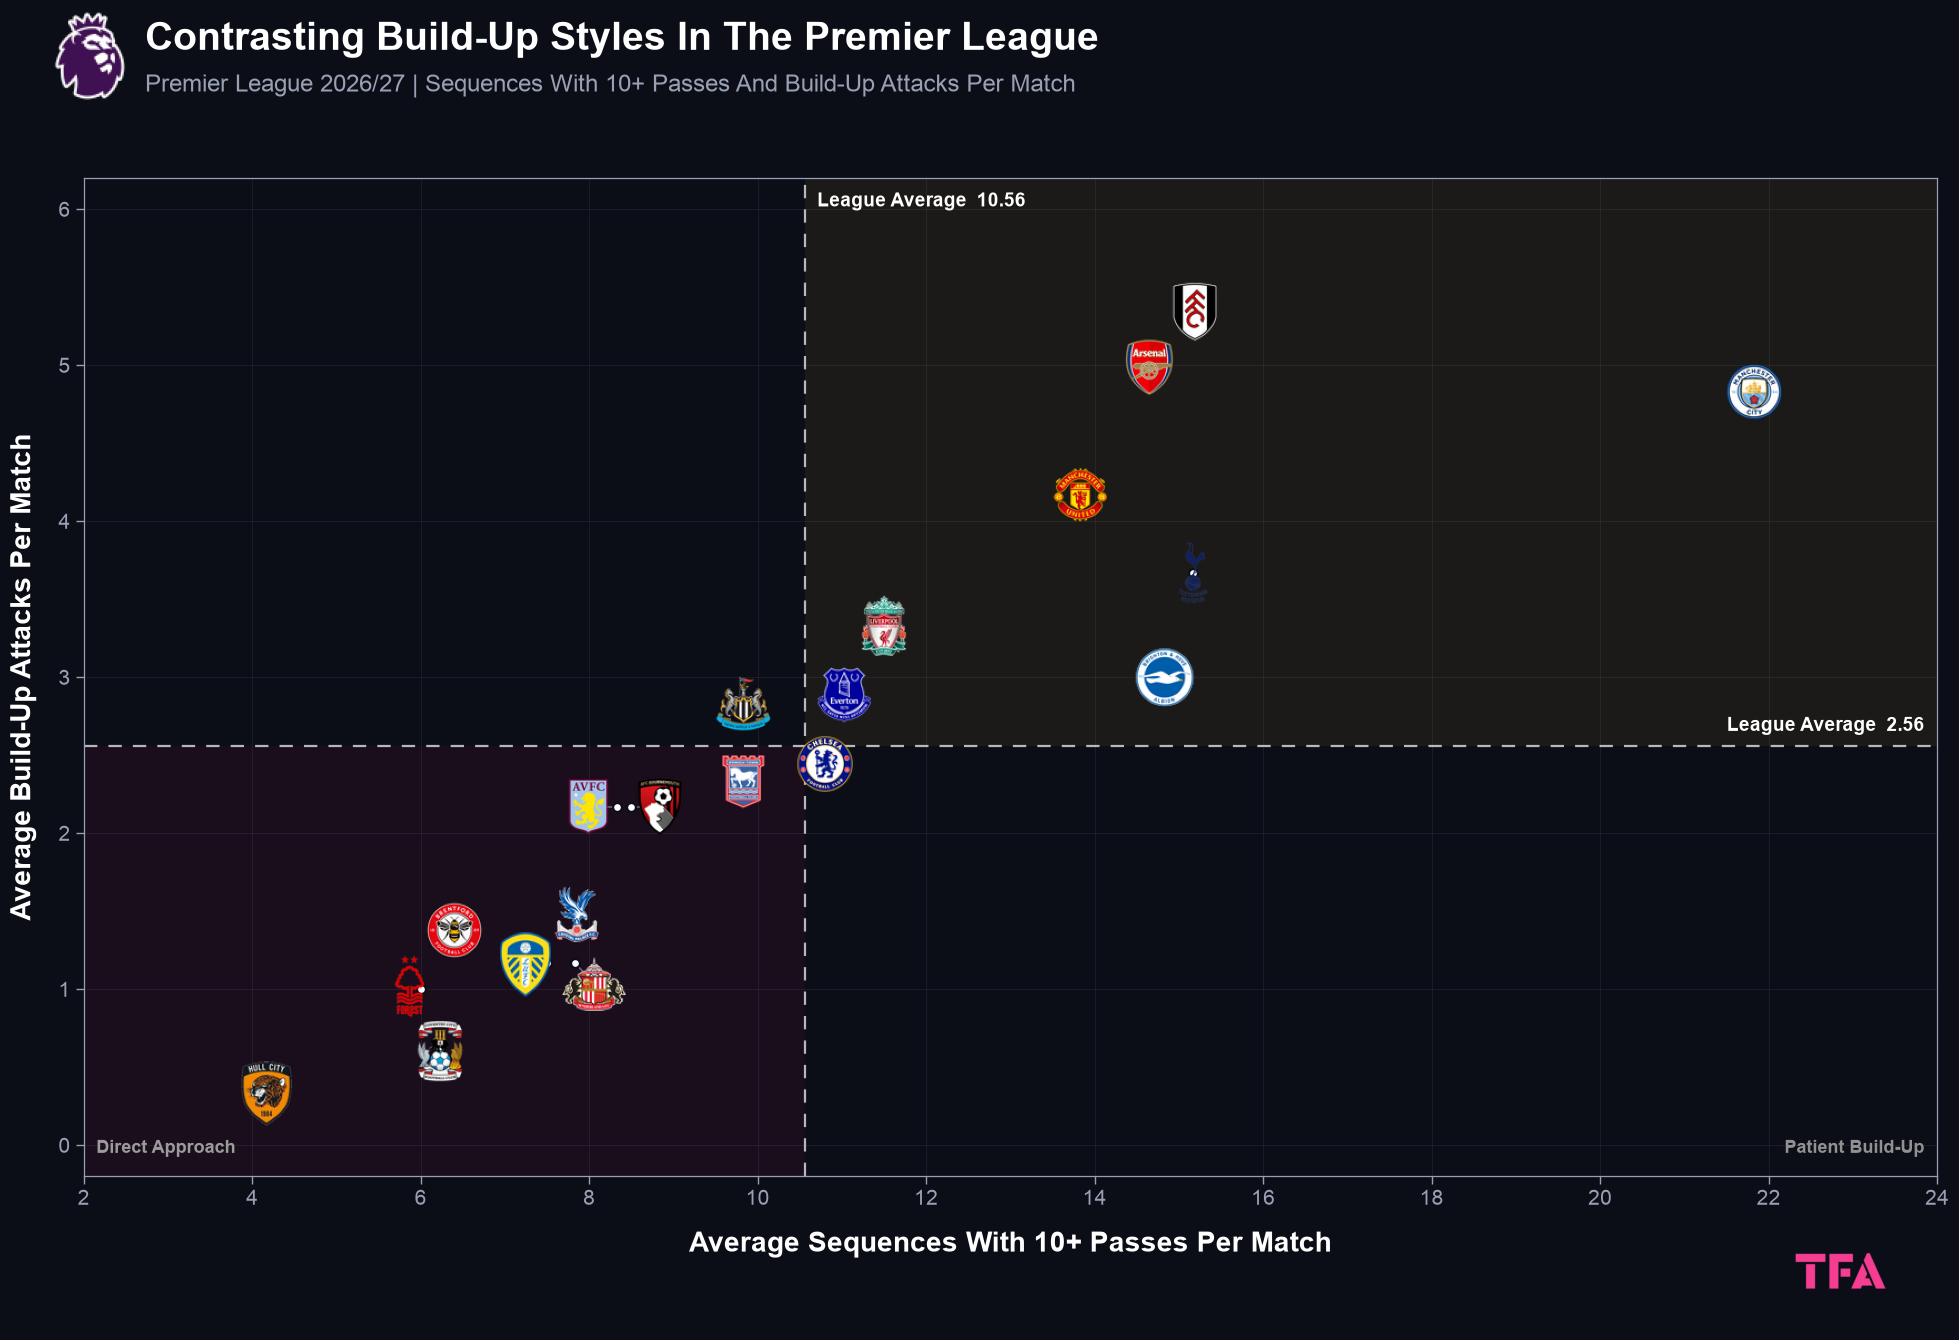

In [10]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.patches import Rectangle
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

DATA = [
    ("Fulham", 15.17, 5.33), ("Arsenal", 14.67, 5.00), ("Manchester City", 21.83, 4.83),
    ("Manchester United", 13.83, 4.17), ("Tottenham Hotspur", 15.17, 3.67), ("Liverpool", 11.50, 3.33),
    ("Brighton", 14.83, 3.00), ("Newcastle United", 9.83, 2.83), ("Everton", 11.00, 2.83),
    ("Chelsea", 10.83, 2.50), ("Ipswich Town", 9.83, 2.33), ("Bournemouth", 8.50, 2.17),
    ("Aston Villa", 8.33, 2.17), ("Brentford", 6.33, 1.33), ("Crystal Palace", 7.83, 1.33),
    ("Sunderland", 7.83, 1.17), ("Leeds United", 7.50, 1.17), ("Nottingham Forest", 6.00, 1.00),
    ("Coventry City", 6.17, 0.67), ("Hull City", 4.17, 0.33),
]

names = [d[0] for d in DATA]
xs = np.array([d[1] for d in DATA])
ys = np.array([d[2] for d in DATA])
avg_x = xs.mean()
avg_y = ys.mean()
n = len(DATA)

DPI = 100
W, H = 2048, 1536
LOGO_PX = 58

XL = (2, 24)
YL = (-0.2, 6.2)
AX_RECT = [0.075, 0.115, 0.905, 0.65]

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def load_resized(path, size_px):
    img = Image.open(path).convert("RGBA")
    ratio = size_px / max(img.width, img.height)
    img = img.resize((max(1, int(img.width * ratio)), max(1, int(img.height * ratio))), Image.LANCZOS)
    return np.asarray(img)


fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")

ax = fig.add_axes(AX_RECT)
ax.set_xlim(*XL)
ax.set_ylim(*YL)
ax.set_xticks(range(2, 25, 2))
ax.set_yticks(range(0, 7, 1))
ax.tick_params(colors="#9AA0B4", labelsize=15, length=6, width=1)
ax.grid(True, color="#9AA0B4", alpha=0.10, linewidth=0.8)
ax.set_axisbelow(True)
for spine in ax.spines.values():
    spine.set_color("#9AA0B4")
    spine.set_linewidth(0.9)
ax.set_xlabel("Average Sequences With 10+ Passes Per Match", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)
ax.set_ylabel("Average Build-Up Attacks Per Match", color="#FFFFFF", fontsize=20, fontweight="bold", labelpad=16)

ax.add_patch(Rectangle((avg_x, avg_y), XL[1] - avg_x, YL[1] - avg_y, facecolor="#F4C430", alpha=0.07, edgecolor="none", zorder=0))
ax.add_patch(Rectangle((XL[0], YL[0]), avg_x - XL[0], avg_y - YL[0], facecolor="#EC1C6C", alpha=0.07, edgecolor="none", zorder=0))

ax.axvline(avg_x, color="#FFFFFF", linestyle=(0, (6, 5)), linewidth=1.6, alpha=0.7, zorder=2)
ax.axhline(avg_y, color="#FFFFFF", linestyle=(0, (6, 5)), linewidth=1.6, alpha=0.7, zorder=2)
ax.text(avg_x + 0.15, 6.05, f"League Average  {avg_x:.2f}", color="#FFFFFF", fontsize=14, fontweight="bold", ha="left", va="center", zorder=5)
ax.text(23.85, avg_y + 0.13, f"League Average  {avg_y:.2f}", color="#FFFFFF", fontsize=14, fontweight="bold", ha="right", va="center", zorder=5)

ax.text(23.85, -0.02, "Patient Build-Up", color="#919191", fontsize=13, fontweight="bold", ha="right", va="center", zorder=5)
ax.text(2.15, -0.02, "Direct Approach", color="#9C9B9B", fontsize=13, fontweight="bold", ha="left", va="center", zorder=5)

ax.scatter(xs, ys, s=40, color="#FFFFFF", edgecolor="#0B0E17", linewidth=1.5, zorder=4)

pts = ax.transData.transform(np.column_stack([xs, ys]))
pos = pts.copy()
bbox = ax.get_window_extent()
scale = np.array([72.0, 72.0])
pad = 44

for _ in range(1500):
    moved = False
    for i in range(n):
        for j in range(i + 1, n):
            d = (pos[j] - pos[i]) / scale
            sd = np.hypot(d[0], d[1])
            if sd < 1:
                if sd < 1e-6:
                    d = np.array([1.0, 0.5])
                    sd = np.hypot(d[0], d[1])
                vec = d / sd * (1 - sd) / 2 * scale
                pos[i] -= vec
                pos[j] += vec
                moved = True
    pos += (pts - pos) * 0.012
    pos[:, 0] = np.clip(pos[:, 0], bbox.x0 + pad, bbox.x1 - pad)
    pos[:, 1] = np.clip(pos[:, 1], bbox.y0 + pad, bbox.y1 - pad)
    if not moved:
        break

logo_data = ax.transData.inverted().transform(pos)

for i in range(n):
    shift = np.hypot(*(pos[i] - pts[i]))
    if shift > 18:
        ax.plot([xs[i], logo_data[i][0]], [ys[i], logo_data[i][1]], color="#9AA0B4", alpha=0.6, linewidth=1.2, zorder=3)
    path = find_logo(names[i])
    if path:
        box = OffsetImage(load_resized(path, LOGO_PX), zoom=0.8)
        ab = AnnotationBbox(box, (logo_data[i][0], logo_data[i][1]), frameon=False, box_alignment=(0.5, 0.5), zorder=6)
        ax.add_artist(ab)
    else:
        ax.text(logo_data[i][0], logo_data[i][1], names[i], color="#FFFFFF", fontsize=11, ha="center", va="center", zorder=6)

fig.text(0.105, 0.855, "Contrasting Build-Up Styles In The Premier League", color="#FFFFFF", fontsize=28, fontweight="bold", ha="left", va="center")
fig.text(0.105, 0.825, "Premier League 2026/27 | Sequences With 10+ Passes And Build-Up Attacks Per Match", color="#9AA0B4", fontsize=17, ha="left", va="center")

ax_tfa = fig.add_axes([0.904, 0.015, 0.077, 0.077])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.04, 0.814, 0.061, 0.061])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

plt.show()

Direct-Attack Speed And Passes Per Sequence In The Premier League 2026-2027

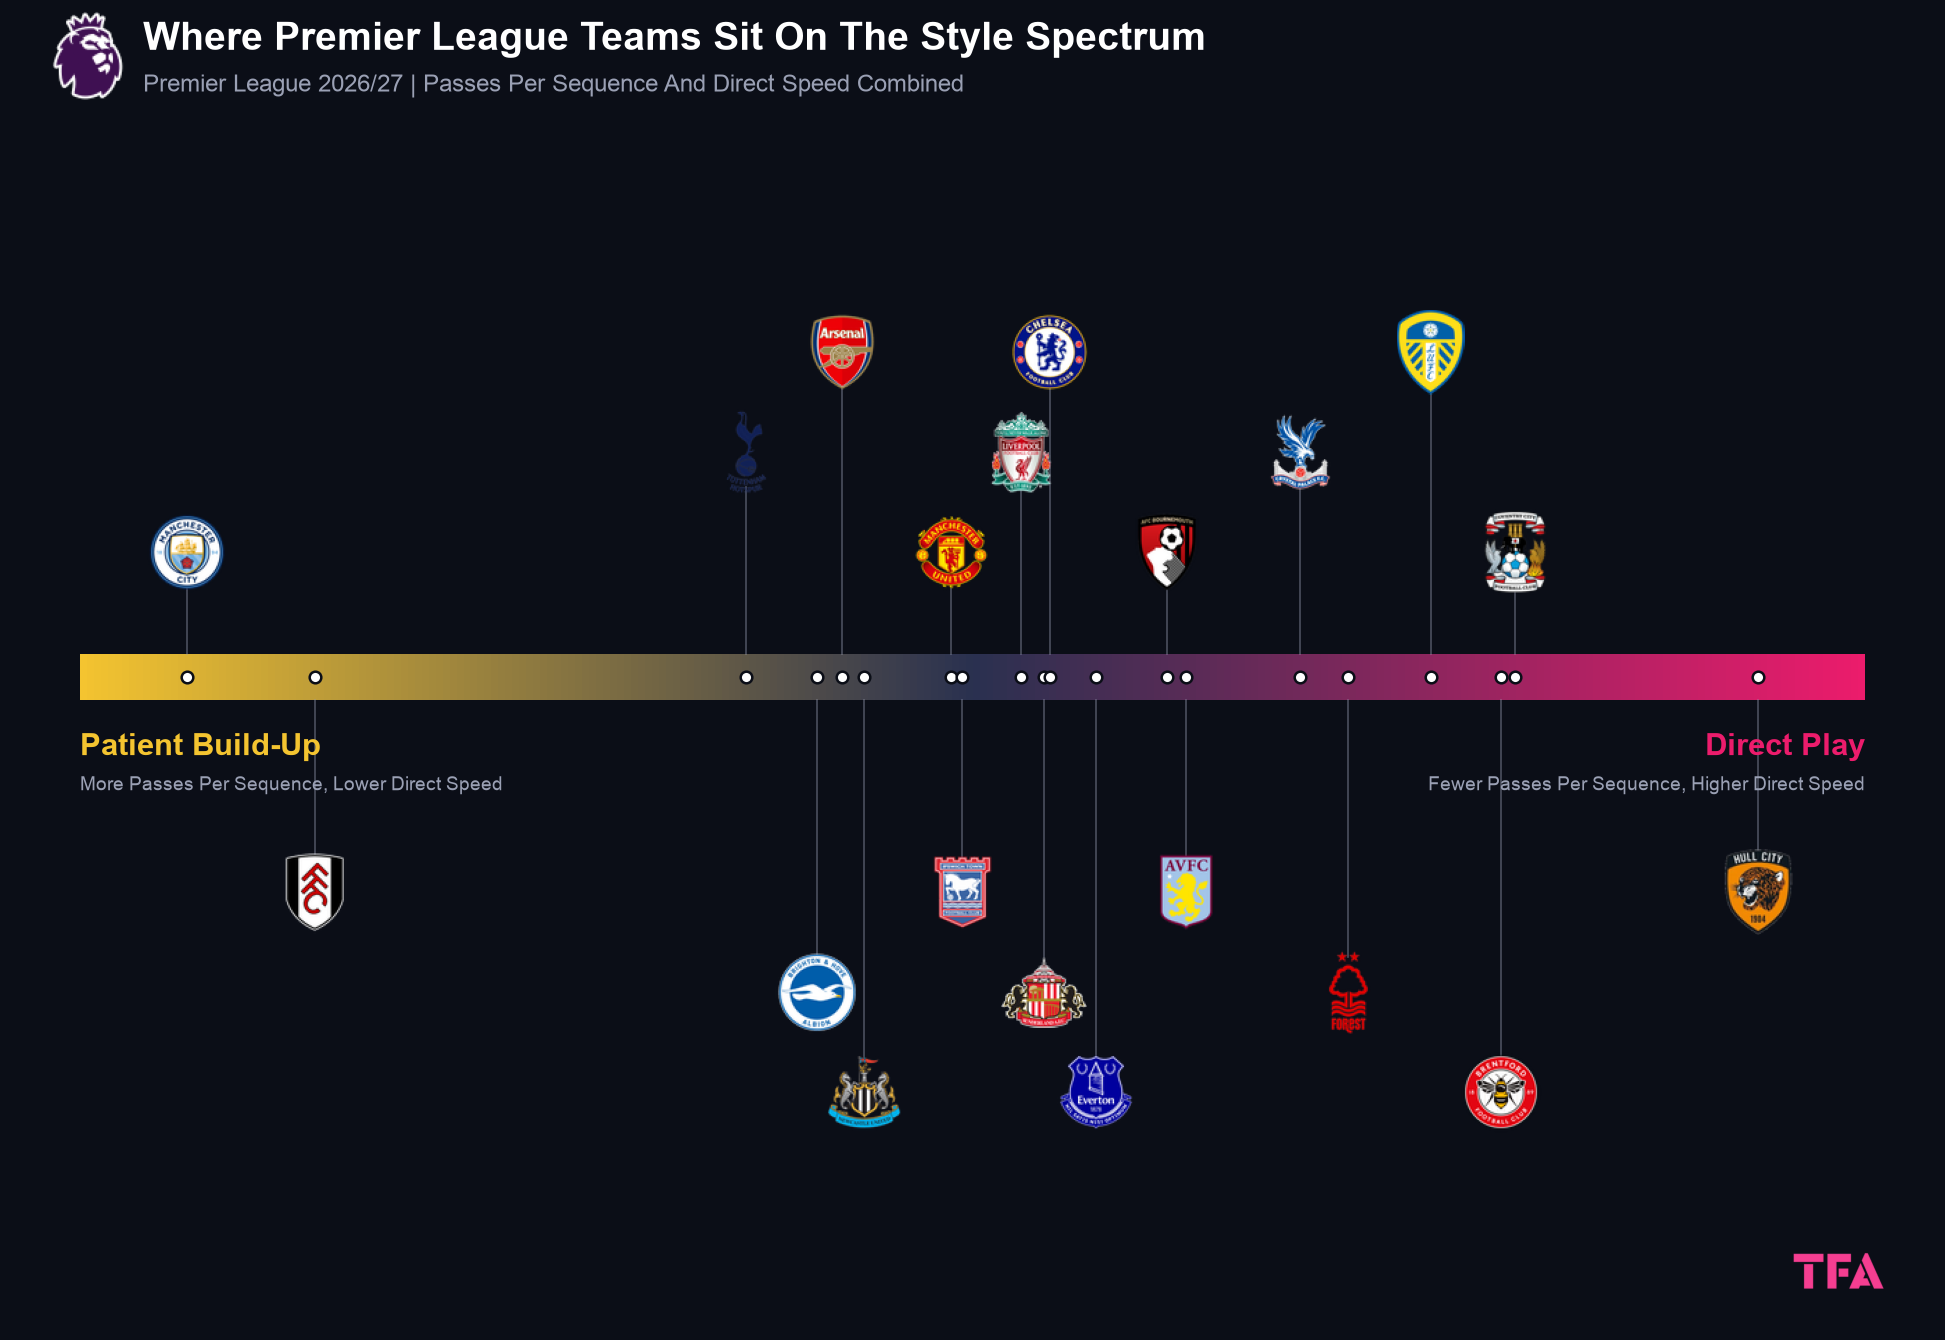

In [12]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import os

BASE = "/Users/mustapha/Documents/Work/Data Analysis TFA/87 Premier league build-up?"
EPL_LOGO = os.path.join(BASE, "Main files", "#EPL Logo.png")
TFA_LOGO = os.path.join(BASE, "Main files", "TFA.png")
LOGOS_DIR = os.path.join(BASE, "Logos")

DATA = [
    ("Fulham", 1.38, 4.36), ("Arsenal", 1.83, 4.23), ("Manchester City", 1.47, 5.05),
    ("Manchester United", 1.91, 4.16), ("Tottenham Hotspur", 1.72, 4.16), ("Liverpool", 1.86, 3.78),
    ("Brighton", 1.74, 4.01), ("Newcastle United", 1.66, 3.60), ("Everton", 1.86, 3.55),
    ("Chelsea", 1.82, 3.56), ("Ipswich Town", 1.73, 3.53), ("Bournemouth", 1.82, 3.20),
    ("Aston Villa", 1.85, 3.24), ("Brentford", 2.00, 2.77), ("Crystal Palace", 1.98, 3.32),
    ("Sunderland", 1.70, 3.18), ("Leeds United", 1.98, 2.92), ("Nottingham Forest", 1.94, 3.04),
    ("Coventry City", 2.04, 2.86), ("Hull City", 2.19, 2.61),
]

names = [d[0] for d in DATA]
speed = np.array([d[1] for d in DATA])
passes = np.array([d[2] for d in DATA])

z_speed = (speed - speed.mean()) / speed.std()
z_passes = (passes - passes.mean()) / passes.std()
raw = (z_speed - z_passes) / 2
score = 6 + (raw - raw.min()) / (raw.max() - raw.min()) * 88

order = np.argsort(score)

DPI = 100
W, H = 2048, 1536
LOGO_PX = 62

AX_RECT = [0.04, 0.115, 0.94, 0.65]
AX_W = AX_RECT[2] * W
AX_H = AX_RECT[3] * H
BAR_Y = AX_H / 2
BAR_H = 46
MARGIN = 70
BAR_L = MARGIN
BAR_R = AX_W - MARGIN
LEVELS = [105, 205, 305]

plt.rcParams.update({
    "figure.dpi": DPI,
    "figure.facecolor": "#0B0E17",
    "savefig.facecolor": "#0B0E17",
    "axes.facecolor": "#0B0E17",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
})


def find_logo(display_name):
    exact = os.path.join(LOGOS_DIR, f"{display_name}.png")
    if os.path.exists(exact):
        return exact
    for file in os.listdir(LOGOS_DIR):
        stem, ext = os.path.splitext(file)
        if stem.strip().lower() == display_name.lower() and ext.lower() in (".png", ".jpg", ".jpeg", ".webp"):
            return os.path.join(LOGOS_DIR, file)
    return None


def load_resized(path, size_px):
    img = Image.open(path).convert("RGBA")
    ratio = size_px / max(img.width, img.height)
    img = img.resize((max(1, int(img.width * ratio)), max(1, int(img.height * ratio))), Image.LANCZOS)
    return np.asarray(img)


fig = plt.figure(figsize=(W / DPI, H / DPI), dpi=DPI, facecolor="#0B0E17")
ax = fig.add_axes(AX_RECT)

cmap = LinearSegmentedColormap.from_list("style", ["#F4C430", "#2A3150", "#EC1C6C"])
ax.imshow(np.linspace(0, 1, 512).reshape(1, -1), extent=[BAR_L, BAR_R, BAR_Y + BAR_H / 2, BAR_Y - BAR_H / 2], aspect="auto", cmap=cmap, zorder=2)

ax.set_xlim(0, AX_W)
ax.set_ylim(AX_H, 0)
ax.axis("off")

ax.text(BAR_L, BAR_Y + 70, "Patient Build-Up", color="#F4C430", fontsize=22, fontweight="bold", ha="left", va="center", zorder=5)
ax.text(BAR_R, BAR_Y + 70, "Direct Play", color="#EC1C6C", fontsize=22, fontweight="bold", ha="right", va="center", zorder=5)
ax.text(BAR_L, BAR_Y + 108, "More Passes Per Sequence, Lower Direct Speed", color="#9AA0B4", fontsize=14, ha="left", va="center", zorder=5)
ax.text(BAR_R, BAR_Y + 108, "Fewer Passes Per Sequence, Higher Direct Speed", color="#9AA0B4", fontsize=14, ha="right", va="center", zorder=5)

for rank, i in enumerate(order):
    x = BAR_L + score[i] / 100 * (BAR_R - BAR_L)
    side = -1 if rank % 2 == 0 else 1
    level = LEVELS[(rank // 2) % 3]
    ly = BAR_Y + side * (BAR_H / 2 + level - 40)
    if side == 1:
        ly = BAR_Y - (BAR_H / 2 + level - 40) if False else ly

    y_logo = BAR_Y - (level + 20) if side == -1 else BAR_Y + (level + 20) + 90
    y_line_end = y_logo + (LOGO_PX / 2 + 4) if side == -1 else y_logo - (LOGO_PX / 2 + 4)
    y_line_start = BAR_Y - BAR_H / 2 if side == -1 else BAR_Y + BAR_H / 2

    ax.plot([x, x], [y_line_start, y_line_end], color="#9AA0B4", alpha=0.45, linewidth=1.2, zorder=3)
    ax.scatter([x], [BAR_Y], s=70, color="#FFFFFF", edgecolor="#0B0E17", linewidth=1.8, zorder=4)

    path = find_logo(names[i])
    if path:
        box = OffsetImage(load_resized(path, LOGO_PX), zoom=1)
        ab = AnnotationBbox(box, (x, y_logo), frameon=False, box_alignment=(0.5, 0.5), zorder=6)
        ax.add_artist(ab)
    else:
        ax.text(x, y_logo, names[i], color="#FFFFFF", fontsize=10, ha="center", va="center", zorder=6)

fig.text(0.105, 0.855, "Where Premier League Teams Sit On The Style Spectrum", color="#FFFFFF", fontsize=28, fontweight="bold", ha="left", va="center")
fig.text(0.105, 0.825, "Premier League 2026/27 | Passes Per Sequence And Direct Speed Combined", color="#9AA0B4", fontsize=17, ha="left", va="center")

ax_tfa = fig.add_axes([0.904, 0.015, 0.077, 0.077])
ax_tfa.imshow(np.asarray(Image.open(TFA_LOGO).convert("RGBA")))
ax_tfa.set_anchor("W")
ax_tfa.axis("off")

ax_epl = fig.add_axes([0.04, 0.814, 0.061, 0.061])
ax_epl.imshow(np.asarray(Image.open(EPL_LOGO).convert("RGBA")))
ax_epl.set_anchor("E")
ax_epl.axis("off")

plt.show()